<a href="https://colab.research.google.com/github/Rushi-Vardhan/data-quality-validation-python/blob/main/data_quality_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Quality Analysis & Validation: Telecom Customer Dataset

**Goal:** Profile a real-world dataset, find quality issues, fix them, and document the before/after results.

**Dataset:** Public Telco Customer Churn dataset (Kaggle), 7,043 rows, 21 columns

**Tools:** Python, pandas, NumPy, Matplotlib

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Rushi-Vardhan/data-quality-validation-python/refs/heads/main/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
raw = df.copy()   # keep original for before/after comparison

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [24]:
# Count real nulls
print("Nulls per column:\n", df.isnull().sum())

# Hidden issue: blank strings that look like data but aren't
blank_counts = (df.astype(str).apply(lambda col: col.str.strip() == '')).sum()
print("\nBlank strings per column:\n", blank_counts[blank_counts > 0])

Nulls per column:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank strings per column:
 TotalCharges    11
dtype: int64


In [25]:
# TotalCharges should be numeric but contains blanks
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("TotalCharges nulls after conversion:", df['TotalCharges'].isnull().sum())

# Check why they are null
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

TotalCharges nulls after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [26]:
# Business logic: tenure 0 means no charges yet, so fill with 0
df.loc[df['TotalCharges'].isnull() & (df['tenure'] == 0), 'TotalCharges'] = 0
print("Remaining nulls:", df['TotalCharges'].isnull().sum())

Remaining nulls: 0


In [27]:
issues = {}

issues['negative_tenure'] = (df['tenure'] < 0).sum()
issues['non_positive_monthly_charges'] = (df['MonthlyCharges'] <= 0).sum()
issues['invalid_churn_values'] = (~df['Churn'].isin(['Yes', 'No'])).sum()
issues['invalid_senior_values'] = (~df['SeniorCitizen'].isin([0, 1])).sum()

# Consistency: no internet service means add-on services must also say "No internet service"
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
no_net = df['InternetService'] == 'No'
issues['inconsistent_addon_values'] = (no_net & (df[addons] != 'No internet service').any(axis=1)).sum()

pd.Series(issues, name='violations')

,violations
negative_tenure,0
non_positive_monthly_charges,0
invalid_churn_values,0
invalid_senior_values,0
inconsistent_addon_values,0


tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


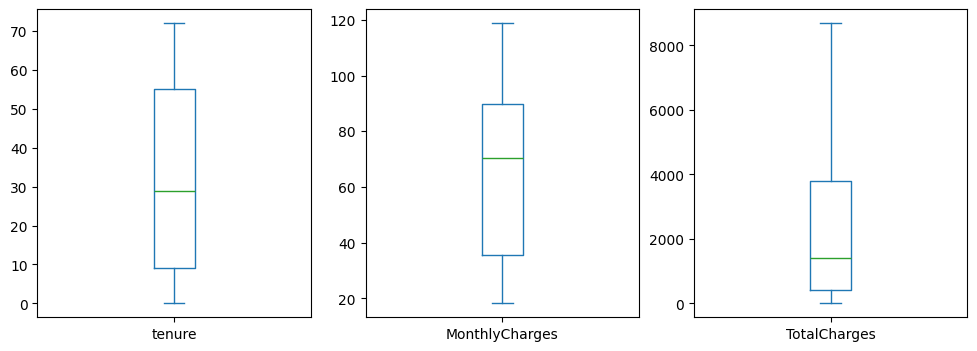

In [28]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(f"{col}: {iqr_outliers(df[col])} outliers")

df[['tenure', 'MonthlyCharges', 'TotalCharges']].plot(kind='box', subplots=True, layout=(1, 3), figsize=(12, 4))
plt.show()

In [29]:
cat_cols = df.select_dtypes(include='object').columns.drop(['customerID'])
for col in cat_cols:
    print(col, "->", df[col].unique())

gender -> ['Female' 'Male']
Partner -> ['Yes' 'No']
Dependents -> ['No' 'Yes']
PhoneService -> ['No' 'Yes']
MultipleLines -> ['No phone service' 'No' 'Yes']
InternetService -> ['DSL' 'Fiber optic' 'No']
OnlineSecurity -> ['No' 'Yes' 'No internet service']
OnlineBackup -> ['Yes' 'No' 'No internet service']
DeviceProtection -> ['No' 'Yes' 'No internet service']
TechSupport -> ['No' 'Yes' 'No internet service']
StreamingTV -> ['No' 'Yes' 'No internet service']
StreamingMovies -> ['No' 'Yes' 'No internet service']
Contract -> ['Month-to-month' 'One year' 'Two year']
PaperlessBilling -> ['Yes' 'No']
PaymentMethod -> ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn -> ['No' 'Yes']


In [30]:
summary = pd.DataFrame({
    'Metric': ['Rows', 'Duplicate rows', 'Total null/blank cells', 'TotalCharges dtype'],
    'Before': [
        len(raw),
        raw.duplicated().sum(),
        (raw.astype(str).apply(lambda c: c.str.strip() == '')).sum().sum() + raw.isnull().sum().sum(),
        str(raw['TotalCharges'].dtype)
    ],
    'After': [
        len(df),
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        str(df['TotalCharges'].dtype)
    ]
})
summary

,Metric,Before,After
0,Rows,7043,7043
1,Duplicate rows,0,0
2,Total null/blank cells,11,0
3,TotalCharges dtype,object,float64


In [31]:
df.to_csv("telco_cleaned.csv", index=False)

## Key Findings

- The dataset has 7,043 rows and no duplicate records or duplicate customer IDs.
- `isnull()` showed 0 missing values, but 11 hidden blank strings were found in `TotalCharges`, which stopped the column from being numeric.
- All 11 affected customers had `tenure = 0` (new customers not yet billed), so I filled them with 0 instead of dropping them or using the mean. This kept all 7,043 rows.
- All 5 validation rules returned 0 violations: no negative tenure, no non-positive monthly charges, no invalid Churn or SeniorCitizen values, and no inconsistent add-on service values for customers without internet.
- Outlier check (IQR method) found 0 outliers in tenure, MonthlyCharges and TotalCharges, and the box plots confirm there are no extreme values.
- Category columns are consistent, with no spelling variations or unexpected values.
- Overall, the only real quality issue was the hidden blank values in `TotalCharges`. After the fix, the dataset passed all checks.